# Week 4: End-to-End Analysis of Sales Data / Data Visualization & Capstone Project

## 1. Load and inspect

In [10]:
import pandas as pd

df=pd.read_csv("sales_data.csv")
df.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
1,Government,Germany,Paseo,NaN,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014
2,Government,Canada,Paseo,NaN,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,1-Nov-13,11,November,2013
3,Government,Germany,Paseo,NaN,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
4,Government,Germany,Velo,NaN,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014


In [11]:
print(df.shape)
print(list(df.columns))
df.info()

(700, 16)
['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Segment              700 non-null    object 
 1   Country              700 non-null    object 
 2   Product              700 non-null    object 
 3   Discount Band        647 non-null    object 
 4   Units Sold           700 non-null    float64
 5   Manufacturing Price  700 non-null    int64  
 6   Sale Price           700 non-null    int64  
 7   Gross Sales          700 non-null    float64
 8   Discounts            700 non-null    float64
 9    Sales               700 non-null    float64
 10  COGS                 700 non-null    float64
 11  Profit               700 n

In [12]:
print("Duplicate rows:", df.duplicated().sum())
print(df.isnull().sum())
df.describe()

Duplicate rows: 0
Segment                 0
Country                 0
Product                 0
Discount Band          53
Units Sold              0
Manufacturing Price     0
Sale Price              0
Gross Sales             0
Discounts               0
 Sales                  0
COGS                    0
Profit                  0
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64


,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Month Number,Year
count,700.000000,700.000000,700.000000,7.000000e+02,700.000000,7.000000e+02,700.000000,700.000000,700.000000,700.000000
mean,1608.294286,96.477143,118.428571,1.827594e+05,13150.354629,1.696091e+05,145475.211429,24133.860371,7.900000,2013.750000
std,867.427859,108.602612,136.775515,2.542623e+05,22962.928775,2.367263e+05,203865.506118,42760.626563,3.377321,0.433322
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,-40617.500000,1.000000,2013.000000
25%,905.000000,5.000000,12.000000,1.739175e+04,800.320000,1.592800e+04,7490.000000,2805.960000,5.750000,2013.750000
50%,1542.500000,10.000000,20.000000,3.798000e+04,2585.250000,3.554020e+04,22506.250000,9242.200000,9.000000,2014.000000
75%,2229.125000,250.000000,300.000000,2.790250e+05,15956.343750,2.610775e+05,245607.500000,22662.000000,10.250000,2014.000000
max,4492.500000,260.000000,350.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,12.000000,2014.000000




The data has 700 rows and 16 columns. There are no duplicates. Discount Band has 53 empty values. The Sales column name has a space in front, and Date is text. Some profits are negative, so some sales lost money.

## 2. Clean the data

In [13]:
df.columns = df.columns.str.strip()
print(list(df.columns))

['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', 'Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']


In [14]:
df["Discount Band"] = df["Discount Band"].fillna("None")
df["Discount Band"].value_counts()

,count
Discount Band,
High,245
Medium,242
Low,160
None,53


In [15]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%y")
print(df["Date"].dtype)
print(df["Date"].min(), df["Date"].max())

datetime64[ns]
2013-09-01 00:00:00 2014-12-01 00:00:00


In [16]:
df["Profit Margin %"] = (df["Profit"] / df["Sales"] * 100).round(2)
df["Profit Margin %"].describe()

,Profit Margin %
count,700.000000
mean,27.900400
std,23.419233
min,-12.940000
25%,13.045000
50%,23.370000
75%,43.180000
max,75.000000


In [17]:
print(df.shape)
print(df.isnull().sum().sum())

(700, 17)
0


In [18]:
df.to_csv("cleaned_sales.csv", index=False)

I removed the extra space from the Sales column name. I filled the empty Discount Band values with "None", because they were the sales with no discount. I changed Date to a real date format. I added a Profit Margin % column (profit divided by sales times 100). No rows were removed, so there are still 700 rows.


## 3. Explore the data.




Question 1: Which customer group earns the most?

In [19]:
pd.options.display.float_format = "{:,.0f}".format

In [20]:
segment = df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)
segment

,Sales,Profit
Segment,,
Government,"52,504,261","11,388,173"
Small Business,"42,427,918","4,143,168"
Channel Partners,"1,800,594","1,316,803"
Midmarket,"2,381,883","660,103"
Enterprise,"19,611,694","-614,546"


Question 2: Which product earns the most?

In [21]:
product = df.groupby("Product")[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)
product

,Sales,Profit
Product,,
Paseo,"33,011,144","4,797,438"
VTT,"20,511,921","3,034,608"
Amarilla,"17,747,116","2,814,104"
Velo,"18,250,059","2,305,992"
Montana,"15,390,802","2,114,755"
Carretera,"13,815,308","1,826,805"


Question 3: Which country sells the most?

In [22]:
country = df.groupby("Country")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
country

,Sales,Profit
Country,,
United States of America,"25,029,830","2,995,541"
Canada,"24,887,655","3,529,229"
France,"24,354,172","3,781,021"
Germany,"23,505,341","3,680,389"
Mexico,"20,949,352","2,907,523"


Question 4: Do discounts hurt profit?

In [23]:
df.groupby("Discount Band")[["Sales", "Profit"]].sum()

,Sales,Profit
Discount Band,,
High,"37,372,487","3,388,867"
Low,"34,629,779","6,188,858"
Medium,"38,780,431","5,579,523"
None,"7,943,654","1,736,455"


Question 5: Why do some sales lose money?

In [24]:
losses = df[df["Profit"] < 0]
print("Loss-making rows:", len(losses))
print(losses["Segment"].value_counts())
print(losses["Discount Band"].value_counts())

Loss-making rows: 58
Segment
Enterprise    58
Name: count, dtype: int64
Discount Band
High      33
Medium    25
Name: count, dtype: int64


Question 6: What is the profit margin by customer group?

In [25]:
df.groupby("Segment")["Profit Margin %"].mean().round(2)

,Profit Margin %
Segment,
Channel Partners,73
Enterprise,-3
Government,29
Midmarket,28
Small Business,10


Chart 1: Profit by segment

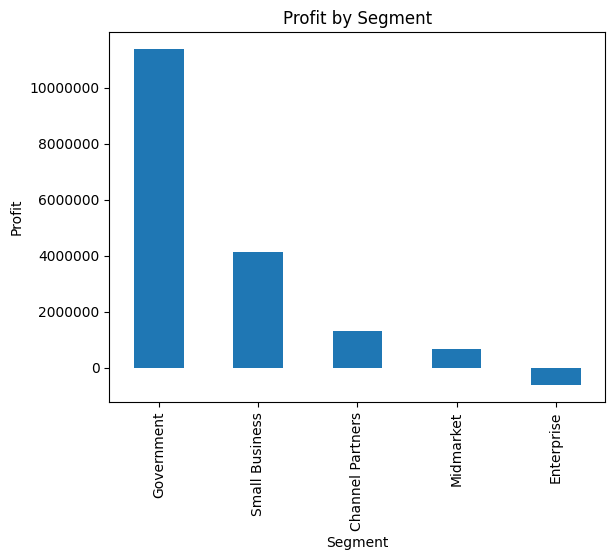

In [26]:
import matplotlib.pyplot as plt

segment["Profit"].plot(kind="bar", title="Profit by Segment")
plt.ylabel("Profit")
plt.ticklabel_format(style="plain", axis="y")   # show full numbers
plt.show()

Chart 2: Profit by product

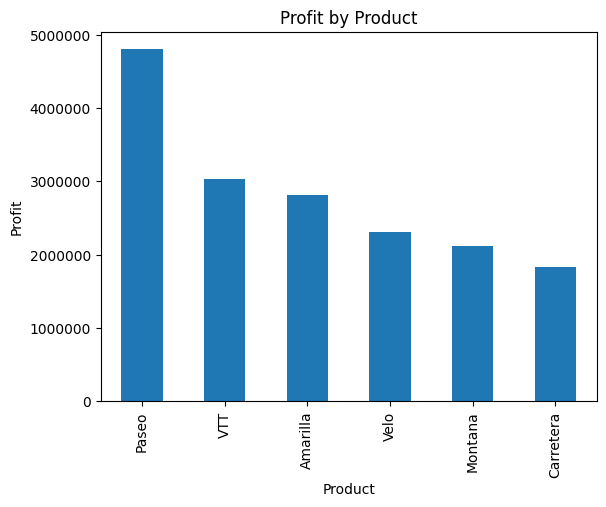

In [27]:
product["Profit"].plot(kind="bar", title="Profit by Product")
plt.ylabel("Profit")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

Chart 3: Sales each month

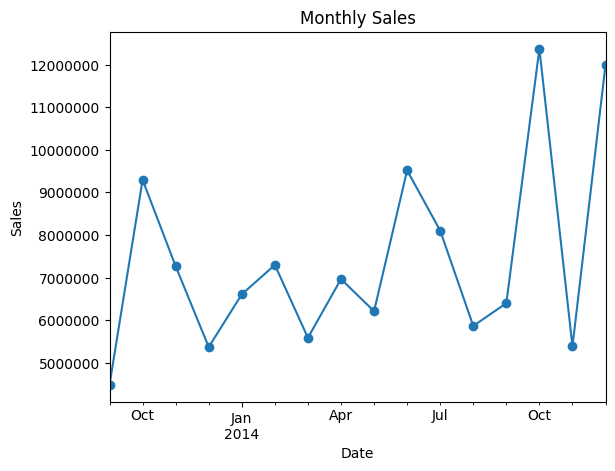

In [28]:
df.groupby("Date")["Sales"].sum().plot(kind="line", marker="o", title="Monthly Sales")
plt.ylabel("Sales")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

Chart 4: Correlation

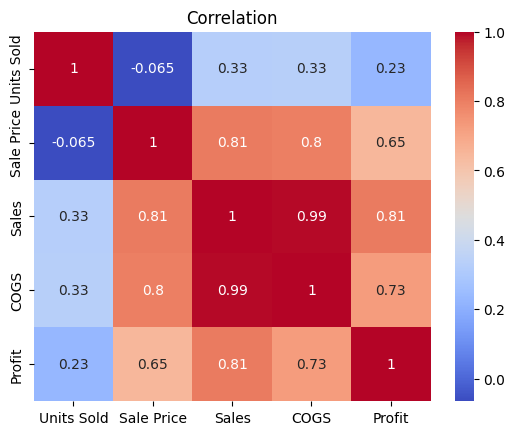

In [29]:
import seaborn as sns

cols = ["Units Sold", "Sale Price", "Sales", "COGS", "Profit"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation")
plt.show()

## What I found
- Government earns the most profit (about 11.4 million). Enterprise loses money (about -0.6 million) even though it has about 19.6 million in sales.
- All 58 loss-making sales are Enterprise, and all had a High or Medium discount.
- Paseo is the best product and Carretera is the weakest.
- High discounts give about half the profit of low discounts for similar sales.
- The best months were October and December 2014.

# 4: Analysis with Pandas

### A. Key numbers for the whole company

In [30]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_units = df["Units Sold"].sum()
margin = total_profit / total_sales * 100

print("Total sales:", round(total_sales))
print("Total profit:", round(total_profit))
print("Units sold:", total_units)
print("Overall margin %:", round(margin, 2))

Total sales: 118726350
Total profit: 16893702
Units sold: 1125806.0
Overall margin %: 14.23


### B. Did sales grow? (Sep to Dec 2014 vs Sep to Dec 2013)

In [31]:
# take only sep, oct, nov, dec
sep_dec = df[df["Month Number"] >= 9]

by_year = sep_dec.groupby("Year")[["Sales", "Profit"]].sum()
print(by_year)

# growth in percent = (new - old) / old * 100
sales_2013 = by_year.loc[2013, "Sales"]
sales_2014 = by_year.loc[2014, "Sales"]
profit_2013 = by_year.loc[2013, "Profit"]
profit_2014 = by_year.loc[2014, "Profit"]

sales_growth = (sales_2014 - sales_2013) / sales_2013 * 100
profit_growth = (profit_2014 - profit_2013) / profit_2013 * 100

print("Sales growth %:", round(sales_growth, 1))
print("Profit growth %:", round(profit_growth, 1))

          Sales    Profit
Year                     
2013 26,415,256 3,878,465
2014 36,157,519 5,435,484
Sales growth %: 36.9
Profit growth %: 40.1


### C. Best and worst individual sales

In [32]:
cols = ["Segment", "Country", "Product", "Discount Band", "Sales", "Profit"]

# sort by profit, biggest first
best = df.sort_values("Profit", ascending=False).head(5)
print(best[cols])

# sort by profit, smallest first
worst = df.sort_values("Profit").head(5)
print(worst[cols])

       Segment                   Country   Product Discount Band     Sales  \
24  Government  United States of America     Paseo           Low 1,159,200   
6   Government                    France  Amarilla          None   962,500   
20  Government                   Germany  Amarilla           Low 1,017,338   
15  Government                   Germany      Velo           Low 1,017,338   
17  Government                   Germany       VTT           Low   986,811   

    Profit  
24 262,200  
6  247,500  
20 246,178  
15 246,178  
17 238,791  
        Segment                   Country    Product Discount Band   Sales  \
581  Enterprise                    Canada        VTT          High 313,862   
570  Enterprise                   Germany  Carretera          High 293,994   
564  Enterprise  United States of America   Amarilla          High 305,730   
553  Enterprise                    Mexico  Carretera          High 303,258   
577  Enterprise  United States of America       Velo          H

### D. Which segment and product work well together?

In [33]:
table = pd.pivot_table(df, values="Profit", index="Segment", columns="Product", aggfunc="sum")
table.round(0)

Product,Amarilla,Carretera,Montana,Paseo,VTT,Velo
Segment,,,,,,
Channel Partners,"230,068","208,406","192,458","331,838","219,766","134,267"
Enterprise,"-95,152","-222,712","-31,096","-81,740","-99,082","-84,762"
Government,"2,208,302","1,398,994","1,126,201","3,057,291","1,840,654","1,756,732"
Midmarket,"63,605","94,105","83,879","258,739","91,121","68,653"
Small Business,"407,281","348,012","743,314","1,231,310","982,150","431,102"


### E. Why does Enterprise lose money?

In [34]:

ent = df[df["Segment"] == "Enterprise"]
print(ent.groupby("Discount Band")[["Sales", "Profit"]].sum())


# how much of sales goes to costs (cogs)
seg = df.groupby("Segment")[["Sales", "COGS"]].sum()
seg["COGS %"] = seg["COGS"] / seg["Sales"] * 100
print(seg["COGS %"])

                  Sales   Profit
Discount Band                   
High          6,528,971 -622,369
Low           6,442,216  101,776
Medium        5,115,508 -154,952
None          1,525,000   61,000
Segment
Channel Partners    27
Enterprise         103
Government          78
Midmarket           72
Small Business      90
Name: COGS %, dtype: float64


### F. Which months sold the most?

In [35]:
monthly = df.groupby("Date")["Sales"].sum()
print(monthly.sort_values(ascending=False).head(3))

Date
2014-10-01   12,375,820
2014-12-01   11,998,788
2014-06-01    9,518,894
Name: Sales, dtype: float64


## What I found in the analysis
- Total sales about 118.7 million, profit about 16.9 million, margin 14.2%
- Same months (Sep-Dec) 2014 vs 2013: sales up about 37%, profit up about 40%
- Best sales are all Government, worst are all Enterprise with high discount
- Enterprise loses money on every product, costs are 103% of its sales
- Enterprise only makes a profit with low or no discount
- Best months: Oct 2014, Dec 2014, Jun 2014

# 5. Regression model to predict sales
I will use Units Sold and Sale Price to predict Sales. I train on 80% of the data and test on the other 20%.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# columns I will use to predict
features = df[["Units Sold", "Sale Price"]]

# the column I want to predict
target = df["Sales"]

print(features.head())

x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

print("Train rows:", len(x_train))
print("Test rows:", len(x_test))

   Units Sold  Sale Price
0       1,513         350
1       1,006         350
2       1,725         350
3       1,513         350
4       1,006         350
Train rows: 560
Test rows: 140


In [37]:
model = LinearRegression()
model.fit(x_train, y_train)

print("Units Sold:", round(model.coef_[0], 2))
print("Sale Price:", round(model.coef_[1], 2))
print("Start number:", round(model.intercept_, 2))

predictions = model.predict(x_test)
print(predictions[:5])

Units Sold: 105.55
Sale Price: 1448.22
Start number: -169383.8
[-70436.50860597 355121.38951044 154331.8052649   20023.94693335
  54143.38589202]


R2 score: 0.7625
Average mistake: 83636


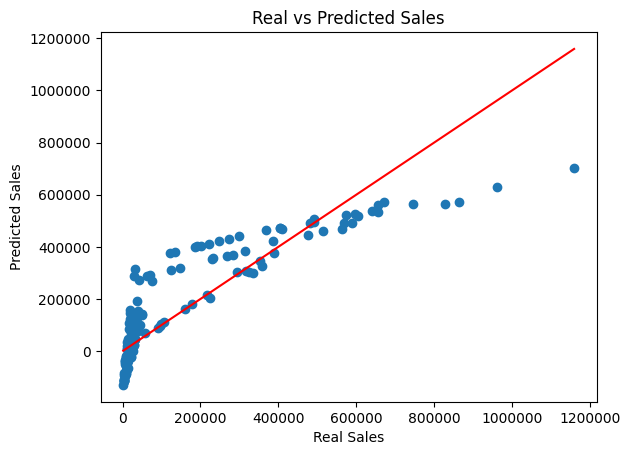

In [38]:
r2 = r2_score(y_test, predictions)
error = mean_absolute_error(y_test, predictions)

print("R2 score:", round(r2, 4))
print("Average mistake:", round(error))

plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Real Sales")
plt.ylabel("Predicted Sales")
plt.title("Real vs Predicted Sales")
plt.ticklabel_format(style="plain")
plt.show()

- R2 score is 0.76, so the model explains about 76% of the sales
- Average mistake is about 83,600, which is big because the average sale is about 169,600
- Sales is units times price, and a straight line model can't match that fully

# 6. Summary and recommendations

### What I found
- Total sales are about 118.7 million and profit is about 16.9 million. Profit margin is 14.2%.
- Government makes the most profit (about 11.4 million).
- Enterprise loses money (about -0.6 million). Its costs are 103% of its sales.
- All 58 loss-making sales are Enterprise, and they all had a high or medium discount.
- Enterprise only makes a profit with low or no discount.
- High discount sales make about half the profit of low discount sales.
- Paseo is the best product and Carretera is the weakest.
- For Sep to Dec, sales in 2014 were about 37% higher than in 2013, and profit was about 40% higher.
- The best months were October 2014 and December 2014.
- The regression model gets an R2 of 0.76 using units and price, so it explains about 76% of sales. The average mistake is about 83,600, so it is okay but not very accurate.

### What I recommend
- Check the prices and discounts for Enterprise, because that group loses money
- Give Enterprise fewer high and medium discounts
- Keep the focus on Government and on the Paseo product
- Get ready for October and December, which are the busiest months
- Look at why Carretera makes the least profit
- If the company wants better sales predictions, add more information to the model, like discount and customer type

### Limits
- 2013 only has Sep to Dec, so I only compared the same months
- The model only uses units and price, so it is not very accurate